# Analysis of TEcount output (DESeq2)

# Imports

In [1]:
version

               _                           
platform       aarch64-apple-darwin20      
arch           aarch64                     
os             darwin20                    
system         aarch64, darwin20           
status                                     
major          4                           
minor          5.0                         
year           2025                        
month          04                          
day            11                          
svn rev        88135                       
language       R                           
version.string R version 4.5.0 (2025-04-11)
nickname       How About a Twenty-Six      

In [2]:
setwd("..")

In [3]:
renv::init()
renv::activate()
renv::status()

- The project is out-of-sync -- use `renv::status()` for details.
The following package(s) are in an inconsistent state:

 package              installed recorded used
 abind                y         n        y   
 AnnotationDbi        y         n        y   
 ape                  y         n        y   
 aplot                y         n        y   
 askpass              y         n        y   
 base64enc            y         n        y   
 BH                   y         n        y   
 Biobase              y         n        y   
 BiocFileCache        y         n        y   
 BiocGenerics         y         n        y   
 BiocManager          y         n        y   
 BiocParallel         y         n        y   
 BiocVersion          y         n        y   
 biomaRt              y         n        y   
 Biostrings           y         n        y   
 bit                  y         n        y   
 bit64                y         n        y   
 blob                 y         n        y   
 cac

In [4]:
library(DESeq2)
library(dplyr)
library(tidyr)
library(ggplot2)
library(pheatmap)
library(RColorBrewer)
library(clusterProfiler)
library(org.Mm.eg.db)
library(enrichplot)
library(DOSE)
library(biomaRt)

# Set working directory
setwd("TECounts")

Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, is.unsorted, lapply, Map, mapply, match, mget,
    order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank,
    rbind, Reduce, rownames, sapply, saveRDS, table, tapply, unique,
    unsplit, which.max, which.min



Attaching package: ‘S4Vectors’


The following object is masked from ‘package:utils’:

    findMatches


The follo

# Annotation & Filtering

In [5]:
create_count_matrix <- function(count_dir = "TEcounts_output") {
  # List all count table files
  count_files <- list.files(count_dir, pattern = "*.cntTable", full.names = TRUE)
  
  # Filter out low quality samples (l1-5)
  count_files <- count_files[!grepl("l1-5", basename(count_files))]
  
  cat("Found", length(count_files), "count files\n")
  
  # Read and combine all count tables
  count_list <- lapply(count_files, function(file) {
    counts <- read.table(file, header = TRUE, sep = "\t")
    colnames(counts) <- c("gene_id", "counts")
    
    # Clean gene IDs
    counts$gene_id <- gsub('"', '', counts$gene_id)
    
    # Extract sample name
    sample_name <- gsub(".cntTable", "", basename(file))
    
    # Return with sample name
    colnames(counts)[2] <- sample_name
    return(counts)
  })
  
  # Merge all samples
  count_matrix <- Reduce(function(x, y) {
    merge(x, y, by = "gene_id", all = TRUE)
  }, count_list)
  
  # Replace NA with 0
  count_matrix[is.na(count_matrix)] <- 0
  
  # Convert to data frame and set gene_id as rownames
  count_matrix <- as.data.frame(count_matrix)
  rownames(count_matrix) <- count_matrix$gene_id
  count_matrix$gene_id <- NULL
  
  # Convert to numeric matrix for DESeq2
  count_matrix <- as.matrix(count_matrix)
  
  cat("Count matrix dimensions:", dim(count_matrix), "\n")
  cat("Sample names:", colnames(count_matrix), "\n")
  
  return(count_matrix)
}

# Function to annotate and categorize gene IDs
annotate_gene_ids <- function(gene_ids) {
  # Create annotation data frame
  annotations <- data.frame(
    gene_id = gene_ids,
    gene_id_clean = gsub("\\.[0-9]+$", "", gene_ids),  # Remove version numbers
    category = "unknown",
    element_type = "unknown",
    family = "unknown",
    stringsAsFactors = FALSE
  )
  
  # Categorize based on ID patterns
  annotations$category <- case_when(
    # Standard Ensembl genes
    grepl("^ENSMUSG", annotations$gene_id_clean) ~ "protein_coding",
    
    # RNA elements
    grepl(":RNA:", annotations$gene_id) ~ "rna_element",
    grepl("^7SK", annotations$gene_id) ~ "rna_element",
    
    # SINE elements
    grepl(":SINE", annotations$gene_id) ~ "sine_element",
    grepl(":Alu", annotations$gene_id) ~ "sine_element",
    grepl("^B[0-9]", annotations$gene_id) ~ "sine_element",
    
    # LINE elements
    grepl(":LINE", annotations$gene_id) ~ "line_element",
    grepl("^L1", annotations$gene_id) ~ "line_element",
    
    # LTR/Retroviral elements
    grepl(":LTR:", annotations$gene_id) ~ "ltr_element",
    grepl(":ERV", annotations$gene_id) ~ "ltr_element",
    grepl("^BGLII", annotations$gene_id) ~ "ltr_element",
    
    # DNA transposons
    grepl(":hAT", annotations$gene_id) ~ "dna_transposon",
    grepl("^Charlie", annotations$gene_id) ~ "dna_transposon",
    grepl("^Arthur", annotations$gene_id) ~ "dna_transposon",
    grepl("^BLACKJACK", annotations$gene_id) ~ "dna_transposon",
    
    # Other repetitive elements
    grepl(":CR1", annotations$gene_id) ~ "other_repetitive",
    grepl("^CR1_", annotations$gene_id) ~ "other_repetitive",
    grepl("^CYRA", annotations$gene_id) ~ "other_repetitive",
    
    TRUE ~ "other"
  )
  
  # Extract element family information
  annotations$family <- case_when(
    grepl("^B[0-9]", annotations$gene_id) ~ "B-family_SINE",
    grepl("^Charlie", annotations$gene_id) ~ "Charlie_hAT",
    grepl("^Arthur", annotations$gene_id) ~ "Arthur_hAT",
    grepl("^L1", annotations$gene_id) ~ "L1_LINE",
    grepl("^BGLII", annotations$gene_id) ~ "BGLII_ERV",
    grepl("^7SK", annotations$gene_id) ~ "7SK_RNA",
    TRUE ~ "other"
  )
  
  # Extract element type
  annotations$element_type <- case_when(
    annotations$category == "protein_coding" ~ "gene",
    annotations$category == "rna_element" ~ "rna",
    annotations$category == "sine_element" ~ "sine",
    annotations$category == "line_element" ~ "line",
    annotations$category == "ltr_element" ~ "ltr",
    annotations$category == "dna_transposon" ~ "dna_transposon",
    annotations$category == "other_repetitive" ~ "repetitive",
    TRUE ~ "other"
  )
  
  return(annotations)
}

# Function to get gene names and descriptions from Ensembl
get_gene_names <- function(ensembl_ids) {
  # Clean Ensembl IDs (remove version numbers)
  clean_ids <- gsub("\\.[0-9]+$", "", ensembl_ids)
  
  # Get unique IDs
  unique_ids <- unique(clean_ids)
  
  cat("Fetching gene names for", length(unique_ids), "unique Ensembl IDs...\n")
  
  tryCatch({
    # Connect to Ensembl mouse database
    mart <- useMart("ensembl", dataset = "mmusculus_gene_ensembl")
    
    # Get gene information
    gene_info <- getBM(
      attributes = c("ensembl_gene_id", "external_gene_name", "gene_biotype", "description"),
      filters = "ensembl_gene_id",
      values = unique_ids,
      mart = mart
    )
    
    cat("Retrieved information for", nrow(gene_info), "genes\n")
    
    return(gene_info)
    
  }, error = function(e) {
    cat("Error fetching gene names:", e$message, "\n")
    return(NULL)
  })
}

# Function to filter genes (remove low counts)
filter_low_counts <- function(count_matrix, min_count = 10, min_samples = 2) {
  # Keep genes with at least min_count reads in at least min_samples
  keep <- rowSums(count_matrix >= min_count) >= min_samples
  filtered_matrix <- count_matrix[keep, ]
  
  cat("Original genes:", nrow(count_matrix), "\n")
  cat("Genes after filtering:", nrow(filtered_matrix), "\n")
  
  return(filtered_matrix)
}

# DESeq2 & plotting functions 

In [6]:
run_deseq2 <- function(count_matrix, metadata, design_formula = ~ group) {
  # Create DESeq2 dataset
  dds <- DESeqDataSetFromMatrix(
    countData = round(count_matrix),
    colData = metadata,
    design = design_formula
  )
  
  # Set reference level (adjust based on your groups)
  dds$group <- relevel(dds$group, ref =  "LFD_1")
  
  # Run DESeq2
  dds <- DESeq(dds)
  
  return(dds)
}

# Function to run DESeq2 on all pairwise comparisons
run_all_deseq2_comparisons <- function(dds, metadata, gene_annotations = NULL, alpha = 0.05, lfc_threshold = 0) {
  groups <- levels(metadata$group)
  n_groups <- length(groups)
  
  cat("Running DESeq2 on all pairwise comparisons...\n")
  cat("Groups:", paste(groups, collapse = ", "), "\n")
  
  all_results <- list()
  
  # Create all pairwise combinations
  for (i in 1:(n_groups-1)) {
    for (j in (i+1):n_groups) {
      group1 <- groups[i]
      group2 <- groups[j]
      
      cat("Comparing", group1, "vs", group2, "...\n")
      
      # Create contrast
      contrast <- c("group", group2, group1)
      
      # Get results with error handling
      tryCatch({
        res <- results(dds, 
                       contrast = contrast,
                       alpha = alpha,
                       lfcThreshold = lfc_threshold)
        
        # Check if results are valid
        if (is.null(res) || nrow(res) == 0) {
          cat("  No results obtained for this comparison\n")
          next
        }
        
        # Convert to data frame and add metadata
        res_df <- as.data.frame(res)
        res_df$gene_id <- rownames(res_df)
        res_df$comparison <- paste(group2, "vs", group1)
        res_df$group1 <- group1
        res_df$group2 <- group2
        
        # Handle NA values in padj and log2FoldChange
        res_df$padj[is.na(res_df$padj)] <- 1  # Set NA p-values to 1 (not significant)
        res_df$log2FoldChange[is.na(res_df$log2FoldChange)] <- 0  # Set NA fold changes to 0
        
        # Add significance column
        res_df$significant <- ifelse(res_df$padj < alpha & abs(res_df$log2FoldChange) > lfc_threshold, 
                                    "Yes", "No")
        
        # Add gene annotations if provided
        if (!is.null(gene_annotations)) {
          # Merge with gene annotations
          res_df <- res_df %>%
            left_join(gene_annotations[, c("gene_id", "external_gene_name", "category", "element_type", "family", "gene_biotype")], 
                     by = "gene_id")
          
          # Create a display name column (gene name if available, otherwise Ensembl ID)
          res_df$display_name <- ifelse(!is.na(res_df$external_gene_name) & res_df$external_gene_name != "", 
                                       res_df$external_gene_name, 
                                       res_df$gene_id)
        }
        
        # Order by adjusted p-value
        res_df <- res_df[order(res_df$padj), ]
        
        # Store results
        comparison_name <- paste(group2, "_vs_", group1, sep = "")
        all_results[[comparison_name]] <- res_df
        
        # Save individual comparison results with gene names
        filename <- paste0("RNAseq_results/DEG/", comparison_name, "_significant_degs.csv")
        write.csv(res_df, filename, row.names = FALSE)
        
        # Count significant genes properly
        sig_count <- sum(res_df$significant == "Yes", na.rm = TRUE)
        cat("  Significant genes:", sig_count, "\n")
        cat("  Total genes:", nrow(res_df), "\n")
        cat("  Upregulated:", sum(res_df$significant == "Yes" & res_df$log2FoldChange > 0, na.rm = TRUE), "\n")
        cat("  Downregulated:", sum(res_df$significant == "Yes" & res_df$log2FoldChange < 0, na.rm = TRUE), "\n")
        
      }, error = function(e) {
        cat("  Error in comparison:", e$message, "\n")
      })
    }
  }
  
  if (length(all_results) == 0) {
    cat("No valid results obtained from any comparison\n")
    return(NULL)
  }
  
  # Create summary table
  summary_table <- do.call(rbind, lapply(names(all_results), function(comp_name) {
    res <- all_results[[comp_name]]
    data.frame(
      Comparison = comp_name,
      Total_Genes = nrow(res),
      Significant_Genes = sum(res$significant == "Yes", na.rm = TRUE),
      Upregulated = sum(res$significant == "Yes" & res$log2FoldChange > 0, na.rm = TRUE),
      Downregulated = sum(res$significant == "Yes" & res$log2FoldChange < 0, na.rm = TRUE)
    )
  }))
  
  write.csv(summary_table, "RNAseq_results/deseq2_summary.csv", row.names = FALSE)
  
  return(all_results)
}

# Function to create volcano plot
create_volcano_plot <- function(de_results, title = "Volcano Plot") {
  # Remove rows with NA values for plotting
  plot_data <- de_results[!is.na(de_results$padj) & !is.na(de_results$log2FoldChange), ]
  
  # Create plot
  p <- ggplot(plot_data, aes(x = log2FoldChange, y = -log10(padj))) +
    geom_point(aes(color = significant), alpha = 0.6) +
    scale_color_manual(values = c("No" = "grey", "Yes" = "red")) +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "blue") +
    geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "blue") +
    labs(title = title,
         x = "log2 Fold Change",
         y = "-log10 Adjusted P-value",
         color = "Significant") +
    theme_minimal() +
    theme(legend.position = "bottom")
  
  return(p)
}

# Function to create heatmap with all samples
create_all_samples_heatmap <- function(dds, de_results, top_n = 50, title = "Top DE Genes Heatmap", 
                                      gene_annotations = NULL) {
  # Get top differentially expressed genes
  top_genes <- de_results %>%
    filter(significant == "Yes") %>%
    arrange(padj) %>%
    head(top_n) %>%
    pull(gene_id)
  
  if (length(top_genes) == 0) {
    cat("No significant genes found for heatmap\n")
    return(NULL)
  }
  
  # Get normalized counts
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)[top_genes, ]
  
  # Handle infinite/NA values
  if (any(!is.finite(plot_data))) {
    plot_data[!is.finite(plot_data)] <- 0
  }
  
  # Create annotations
  annotation_col <- data.frame(
    Group = colData(vsd)$group,
    row.names = colnames(plot_data)
  )
  
  # Add gene names if annotations provided
  if (!is.null(gene_annotations)) {
    gene_info <- gene_annotations[gene_annotations$gene_id %in% rownames(plot_data), 
                                 c("gene_id", "external_gene_name", "category")]
    gene_name_map <- setNames(gene_info$external_gene_name, gene_info$gene_id)
    rownames(plot_data) <- ifelse(is.na(gene_name_map[rownames(plot_data)]), 
                                 rownames(plot_data), 
                                 gene_name_map[rownames(plot_data)])
    
    row_annotation <- data.frame(
      Category = gene_info$category[match(rownames(plot_data), gene_name_map)],
      row.names = rownames(plot_data)
    )
  }
  
  # Create heatmap
  pheatmap(plot_data,
           annotation_col = annotation_col,
           annotation_row = if(exists("row_annotation")) row_annotation else NULL,
           scale = "row",
           show_rownames = TRUE,
           main = paste(title, "(All Samples)"),
           fontsize_row = 8,
           fontsize_col = 10)
}

# Function to create heatmap with just comparison samples
create_comparison_heatmap <- function(dds, de_results, top_n = 50, title = "Top DE Genes Heatmap", 
                                     gene_annotations = NULL, comparison_name = NULL) {
  # Get top differentially expressed genes
  top_genes <- de_results %>%
    filter(significant == "Yes") %>%
    arrange(padj) %>%
    head(top_n) %>%
    pull(gene_id)
  
  if (length(top_genes) == 0) {
    cat("No significant genes found for heatmap\n")
    return(NULL)
  }
  
  # Get normalized counts
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)[top_genes, ]
  
  # Handle infinite/NA values
  if (any(!is.finite(plot_data))) {
    plot_data[!is.finite(plot_data)] <- 0
  }
  
  # Extract groups being compared
  if (!is.null(comparison_name)) {
    groups <- strsplit(comparison_name, "_vs_")[[1]]
    if (length(groups) == 2) {
      group1 <- groups[1]
      group2 <- groups[2]
      
      # Subset to just comparison samples
      group_samples <- colnames(plot_data)[colData(vsd)$group %in% c(group1, group2)]
      plot_data <- plot_data[, group_samples]
      
      # Create annotation for comparison samples - FIXED THIS PART
      annotation_col <- data.frame(
        Group = colData(vsd)$group[match(colnames(plot_data), colnames(assay(vsd)))],
        row.names = colnames(plot_data)
      )
    }
  }
  
  # Add gene names if annotations provided
  if (!is.null(gene_annotations)) {
    gene_info <- gene_annotations[gene_annotations$gene_id %in% rownames(plot_data), 
                                 c("gene_id", "external_gene_name", "category")]
    gene_name_map <- setNames(gene_info$external_gene_name, gene_info$gene_id)
    rownames(plot_data) <- ifelse(is.na(gene_name_map[rownames(plot_data)]), 
                                 rownames(plot_data), 
                                 gene_name_map[rownames(plot_data)])
    
    row_annotation <- data.frame(
      Category = gene_info$category[match(rownames(plot_data), gene_name_map)],
      row.names = rownames(plot_data)
    )
  }
  
  # Create heatmap
  pheatmap(plot_data,
           annotation_col = annotation_col,
           annotation_row = if(exists("row_annotation")) row_annotation else NULL,
           scale = "row",
           show_rownames = TRUE,
           main = paste(title, "(", group2, "vs", group1, "only)"),
           fontsize_row = 8,
           fontsize_col = 10)
}

# Run main analysis

In [7]:
main_analysis <- function() {
  cat("Starting comprehensive RNA-seq analysis...\n")
  
  # 1. Create count matrix
  cat("Creating count matrix...\n")
  count_matrix <- create_count_matrix()
  
  # 2. Import sample metadata
  cat("Importing sample metadata...\n")
  metadata <- read.csv("../sample_metadata.csv")
  
  # 3. Fix sample names in metadata (convert dots to hyphens)
  metadata$sample_id_fixed <- gsub("\\.", "-", metadata$sample_id)
  rownames(metadata) <- metadata$sample_id_fixed
  metadata$group <- factor(metadata$group)
  
  # 4. Remove l1-5 sample from metadata (was filtered out of count matrix)
  metadata <- metadata[metadata$sample_id_fixed != "l1-5", ]
  
  # 5. Annotate gene IDs
  cat("Annotating gene IDs...\n")
  annotations <- annotate_gene_ids(rownames(count_matrix))
  
  # 6. Get gene names for protein coding genes
  protein_coding_ids <- annotations$gene_id_clean[annotations$category == "protein_coding"]
  gene_names <- get_gene_names(protein_coding_ids)
  
  # 7. Add gene names to annotations
  annotations <- annotations %>%
    left_join(gene_names, by = c("gene_id_clean" = "ensembl_gene_id"))
  
  # 8. Create annotated count matrix
  count_matrix_annotated <- as.data.frame(count_matrix)
  count_matrix_annotated$gene_id <- rownames(count_matrix_annotated)
  count_matrix_annotated$gene_id_clean <- annotations$gene_id_clean
  count_matrix_annotated$external_gene_name <- annotations$external_gene_name
  count_matrix_annotated$category <- annotations$category
  count_matrix_annotated$element_type <- annotations$element_type
  count_matrix_annotated$family <- annotations$family
  count_matrix_annotated$gene_biotype <- annotations$gene_biotype
  count_matrix_annotated$description <- annotations$description
  
  # 9. Save annotated count matrix
  write.csv(count_matrix_annotated, "RNAseq_results/count_matrix_annotated.csv", row.names = FALSE)
  
  # 10. Filter low counts
  cat("Filtering low count genes...\n")
  filtered_matrix <- filter_low_counts(count_matrix)
  
  # 11. Create clean count matrix for DESeq2 (numeric only)
  sample_cols <- colnames(filtered_matrix)
  count_matrix_clean <- as.matrix(filtered_matrix)
  rownames(count_matrix_clean) <- rownames(filtered_matrix)
  
  # 12. Run DESeq2
  cat("Running DESeq2...\n")
  dds <- run_deseq2(count_matrix_clean, metadata)
  
  # 13. Run all pairwise comparisons
  cat("Running all pairwise comparisons...\n")
  all_results <- run_all_deseq2_comparisons(dds, metadata, gene_annotations = count_matrix_annotated)
  
  # 14. Create plots for each comparison
  cat("Creating plots for each comparison...\n")
  
  for (comp_name in names(all_results)) {
    cat("Creating plots for", comp_name, "...\n")
    
    de_results <- all_results[[comp_name]]
    
    # Volcano plot
    volcano_plot <- create_volcano_plot(de_results, title = paste("Volcano Plot:", comp_name))
    filename <- paste0("RNAseq_results/volcano plots/volcano_plot_", comp_name, ".png")
    ggsave(filename, volcano_plot, width = 10, height = 8)
    
    # Heatmap with ALL samples
    filename_all <- paste0("RNAseq_results/heatmaps/heatmap_all_samples_", comp_name, ".png")
    png(filename_all, width = 12, height = 10, units = "in", res = 300)
    
    # Create just the all-samples heatmap
    create_all_samples_heatmap(dds, de_results, title = paste("Top DE Genes:", comp_name), 
                              gene_annotations = count_matrix_annotated)
    dev.off()
    
    # Heatmap with just the comparison samples
    filename_comp <- paste0("RNAseq_results/heatmaps/heatmap_comparison_only_", comp_name, ".png")
    png(filename_comp, width = 10, height = 8, units = "in", res = 300)
    
    # Create just the comparison heatmap
    create_comparison_heatmap(dds, de_results, title = paste("Top DE Genes:", comp_name), 
                            gene_annotations = count_matrix_annotated, 
                            comparison_name = comp_name)
    dev.off()
  }
  
  cat("Analysis complete! Results saved in RNAseq_results/ folder.\n")
  
  return(list(
    count_matrix = count_matrix,
    metadata = metadata,
    annotations = annotations,
    count_matrix_annotated = count_matrix_annotated,
    dds = dds,
    all_results = all_results
  ))
}

# Create output directory
dir.create("RNAseq_results", showWarnings = FALSE)

# Run the analysis
results <- main_analysis()

Starting comprehensive RNA-seq analysis...
Creating count matrix...
Found 29 count files
Count matrix dimensions: 57458 29 
Sample names: h1-1 h1-2 h1-3 h1-4 h1-5 h2-1 h2-2 h2-3 h2-4 h2-5 h3-1 h3-2 h3-3 h3-4 h3-5 l1-1 l1-2 l1-3 l1-4 l2-1 l2-2 l2-3 l2-4 l2-5 l3-1 l3-2 l3-3 l3-4 l3-5 
Importing sample metadata...
Annotating gene IDs...
Fetching gene names for 56312 unique Ensembl IDs...
Retrieved information for 51536 genes
Filtering low count genes...
Original genes: 57458 
Genes after filtering: 29590 
Running DESeq2...


converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



Running all pairwise comparisons...
Running DESeq2 on all pairwise comparisons...
Groups: HFD_1, HFD_2, HFD_3, LFD_1, LFD_2, LFD_3 
Comparing HFD_1 vs HFD_2 ...
  Significant genes: 17955 
  Total genes: 29590 
  Upregulated: 8853 
  Downregulated: 9102 
Comparing HFD_1 vs HFD_3 ...
  Significant genes: 4099 
  Total genes: 29590 
  Upregulated: 1772 
  Downregulated: 2327 
Comparing HFD_1 vs LFD_1 ...
  Significant genes: 17 
  Total genes: 29590 
  Upregulated: 1 
  Downregulated: 16 
Comparing HFD_1 vs LFD_2 ...
  Significant genes: 18991 
  Total genes: 29590 
  Upregulated: 9408 
  Downregulated: 9583 
Comparing HFD_1 vs LFD_3 ...
  Significant genes: 3190 
  Total genes: 29590 
  Upregulated: 1362 
  Downregulated: 1828 
Comparing HFD_2 vs HFD_3 ...
  Significant genes: 18498 
  Total genes: 29590 
  Upregulated: 9299 
  Downregulated: 9199 
Comparing HFD_2 vs LFD_1 ...
  Significant genes: 17262 
  Total genes: 29590 
  Upregulated: 8518 
  Downregulated: 8744 
Comparing HFD_2 v

# Specific plots

Creating heatmap for genes of interest...
Available genes in dataset: 29590 
Sample of available gene IDs: 7SK:RNA:RNA AmnSINE1:Deu:SINE AmnSINE2:Deu:SINE Arthur1:hAT-Tip100:DNA Arthur1A:hAT-Tip100:DNA Arthur1B:hAT-Tip100:DNA 
Found 35 out of 37 genes
Missing genes: Ifnb1 Ifna4 
Found gene IDs: ENSMUSG00000027398.13 ENSMUSG00000005824.7 ENSMUSG00000021756.12 ENSMUSG00000025929.4 ENSMUSG00000041872.9 ENSMUSG00000037157.8 ENSMUSG00000020009.13 ENSMUSG00000025383.2 ENSMUSG00000004296.14 ENSMUSG00000016529.5 ENSMUSG00000063376.6 ENSMUSG00000004814.10 ENSMUSG00000000982.5 ENSMUSG00000018930.3 ENSMUSG00000035042.2 ENSMUSG00000035373.2 ENSMUSG00000009185.2 ENSMUSG00000026166.14 ENSMUSG00000018920.11 ENSMUSG00000058427.10 ENSMUSG00000029379.10 ENSMUSG00000029371.7 ENSMUSG00000029417.9 ENSMUSG00000034855.13 ENSMUSG00000060183.6 ENSMUSG00000023078.6 ENSMUSG00000025804.5 ENSMUSG00000049103.14 ENSMUSG00000079227.10 ENSMUSG00000040899.14 ENSMUSG00000037944.8 ENSMUSG00000026180.8 ENSMUSG00000050232.

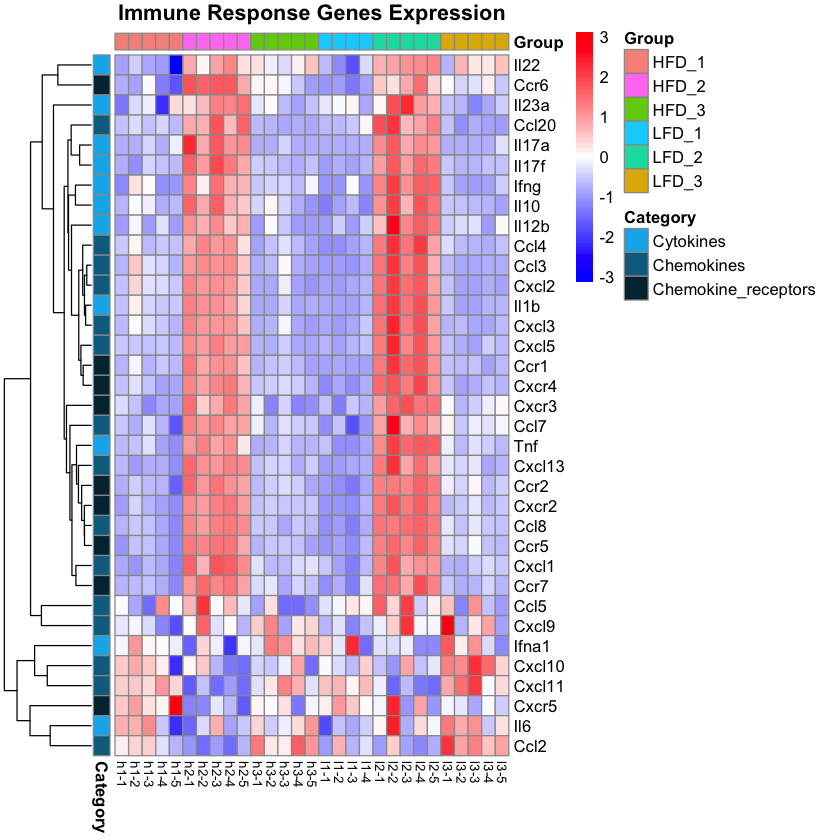

In [8]:
create_gene_of_interest_heatmap <- function(dds, gene_list, gene_annotations = NULL, 
                                           title = "Gene Expression Heatmap", 
                                           filename = NULL) {
  
  # Get normalized counts
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)
  
  cat("Available genes in dataset:", nrow(plot_data), "\n")
  cat("Sample of available gene IDs:", head(rownames(plot_data)), "\n")
  
  # Find genes in the dataset (try both gene names and Ensembl IDs)
  found_genes <- c()
  gene_mapping <- c()
  
  for (gene in gene_list) {
    # Try to find by gene name first
    if (!is.null(gene_annotations)) {
      # Look for exact match in external_gene_name
      gene_match <- gene_annotations$gene_id[gene_annotations$external_gene_name == gene]
      if (length(gene_match) > 0) {
        # Check if this gene ID exists in plot_data
        if (gene_match[1] %in% rownames(plot_data)) {
          found_genes <- c(found_genes, gene_match[1])
          gene_mapping[gene_match[1]] <- gene
          next
        }
      }
      
      # Try partial match (case insensitive)
      gene_match <- gene_annotations$gene_id[grepl(gene, gene_annotations$external_gene_name, ignore.case = TRUE)]
      if (length(gene_match) > 0) {
        # Check if this gene ID exists in plot_data
        if (gene_match[1] %in% rownames(plot_data)) {
          found_genes <- c(found_genes, gene_match[1])
          gene_mapping[gene_match[1]] <- gene
          next
        }
      }
    }
    
    # Try to find by Ensembl ID if it looks like one
    if (grepl("^ENSMUSG", gene)) {
      if (gene %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene)
        gene_mapping[gene] <- gene
      }
    }
  }
  
  cat("Found", length(found_genes), "out of", length(gene_list), "genes\n")
  cat("Missing genes:", setdiff(gene_list, gene_mapping), "\n")
  cat("Found gene IDs:", found_genes, "\n")
  
  if (length(found_genes) == 0) {
    cat("No genes found in the dataset\n")
    return(NULL)
  }
  
  # Verify all found genes exist in plot_data
  missing_in_plot <- setdiff(found_genes, rownames(plot_data))
  if (length(missing_in_plot) > 0) {
    cat("Warning: Some found genes are not in plot_data:", missing_in_plot, "\n")
    # Remove missing genes
    found_genes <- found_genes[found_genes %in% rownames(plot_data)]
    gene_mapping <- gene_mapping[names(gene_mapping) %in% found_genes]
  }
  
  cat("Final genes to plot:", length(found_genes), "\n")
  
  if (length(found_genes) == 0) {
    cat("No valid genes remaining after filtering\n")
    return(NULL)
  }
  
  # Subset data to found genes
  plot_data_subset <- plot_data[found_genes, ]
  
  # Replace rownames with gene names for readability
  rownames(plot_data_subset) <- gene_mapping[rownames(plot_data_subset)]
  
  # Create annotation for samples
  annotation_col <- data.frame(
    Group = colData(vsd)$group,
    row.names = colnames(plot_data_subset)
  )
  
  # Create row annotation for gene categories - FIXED CASE ISSUES
  gene_categories <- data.frame(
    Category = case_when(
      rownames(plot_data_subset) %in% c("Il1b", "Tnf", "Il6", "Il17a", "Il17f", "Il22", "Ifng", "Il23a", "Il12b", "Ifnb1", "Il10", "Ifna1", "Ifna4") ~ "Cytokines",
      rownames(plot_data_subset) %in% c("Ccl2", "Ccl3", "Ccl4", "Ccl5", "Ccl7", "Ccl8", "Ccl20", 
                "Cxcl1", "Cxcl2", "Cxcl3", "Cxcl5", "Cxcl9", "Cxcl10", "Cxcl11", "Cxcl13") ~ "Chemokines",
      rownames(plot_data_subset) %in% c("Ccr1", "Ccr2", "Ccr5", "Ccr6", "Ccr7", "Cxcr2", "Cxcr3", "Cxcr4", "Cxcr5") ~ "Chemokine_receptors",
      TRUE ~ "Other"
    ),
    row.names = rownames(plot_data_subset)
  )
  
  # Create color palette for groups
  group_colors <- c("HFD_1" = "#f69289", "HFD_2" = "#ff81f2", "HFD_3" = "#70cf07",
                    "LFD_1" = "#00d1ff", "LFD_2" = "#00dcaf", "LFD_3" = "#e0b400")
  
  # Create annotation colors
  ann_colors <- list(
    Group = group_colors,
    Category = c("Cytokines" = "#0cb3eb", "Chemokines" = "#096d8f", "Chemokine_receptors" = "#032e3d")
  )
  
  # Create heatmap
  p <- pheatmap(plot_data_subset,
                 annotation_col = annotation_col,
                 annotation_row = gene_categories,
                 annotation_colors = ann_colors,
                 scale = "row",
                 show_rownames = TRUE,
                 main = title,
                 fontsize_row = 10,
                 fontsize_col = 8,
                 cluster_rows = TRUE,
                 cluster_cols = FALSE,
                 color = colorRampPalette(c("blue", "white", "red"))(100))
  
  # Save plot if filename provided
  if (!is.null(filename)) {
    ggsave(filename, p, width = 14, height = 12, dpi = 300)
  }
  
  return(list(
    plot = p,
    found_genes = found_genes,
    gene_mapping = gene_mapping,
    plot_data = plot_data_subset
  ))
}
# Define your genes of interest
cytokines <- c("Il1b", "Tnf", "Il6", "Il17a", "Il17f", "Il22", "Ifng", "Il23a", "Il12b", "Ifnb1", "Il10", "Ifna1", "Ifna4")
chemokines <- c("Ccl2", "Ccl3", "Ccl4", "Ccl5", "Ccl7", "Ccl8", "Ccl20", 
                "Cxcl1", "Cxcl2", "Cxcl3", "Cxcl5", "Cxcl9", "Cxcl10", "Cxcl11", "Cxcl13")
chemokine_receptors <- c("Ccr1", "Ccr2", "Ccr5", "Ccr6", "Ccr7", "Cxcr2", "Cxcr3", "Cxcr4", "Cxcr5")

# All genes of interest
all_genes_of_interest <- c(cytokines, chemokines, chemokine_receptors)

# Create the heatmap
cat("Creating heatmap for genes of interest...\n")
immune_heatmap <- create_gene_of_interest_heatmap(
  dds = results$dds,
  gene_list = all_genes_of_interest,
  gene_annotations = results$count_matrix_annotated,
  title = "Immune Response Genes Expression",
  filename = "RNAseq_results/immune_genes_heatmap.png"
)

# Show summary
if (!is.null(immune_heatmap)) {
  cat("Heatmap created successfully!\n")
  cat("Genes found:", length(immune_heatmap$found_genes), "\n")
  cat("Genes missing:", setdiff(all_genes_of_interest, immune_heatmap$gene_mapping), "\n")
  
  # Save the data used for the heatmap
  write.csv(immune_heatmap$plot_data, "RNAseq_results/immune_genes_expression_data.csv")
}